# B5 – Integrasi: Rangkaian Praproses SIMUTEH

## Langkah 5.1 – Modul `src/praproses.py`

Modul `src/praproses.py` mengimplementasikan pipeline 5-tahap:
1. **Ubah Ukuran (*Resize*)**: Menyeragamkan lebar citra ke 640 piksel dengan mempertahankan aspek rasio (`cv2.INTER_AREA`).
2. **Koreksi Gamma**: Menyesuaikan kurva pencahayaan menggunakan lookup table (`cv2.LUT`).
3. **CLAHE pada Kanal V (HSV)**: Ekualisasi adaptif lokal pada saluran intensitas tanpa mengubah rona (*hue*) alami daun.
4. **Peredaman Derau**: Penapis median 3×3 untuk meredam derau sensor dan impulsif tanpa mengikis bercak kecil.
5. **Penajaman (*Unsharp Masking*)**: Penajaman terkontrol untuk mempertegas kontur tepian bercak.

In [1]:
# Verifikasi pemanggilan modul praproses dan simpan_param
import sys, os
sys.path.insert(0, "../src")
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, tampil, kontras_bercak
from praproses import praproses, simpan_param, PARAM_BAWAAN

DATA_DIR = "../data/sintetis"
os.makedirs("../hasil", exist_ok=True)

print("Parameter bawaan modul praproses:")
for k, v in PARAM_BAWAAN.items():
    print(f"  {k:12s}: {v}")

Parameter bawaan modul praproses:
  lebar       : 640
  gamma       : 1.0
  clahe_clip  : 2.0
  clahe_tile  : 8
  penapis     : median
  kernel      : 3
  sigma       : 1.0
  tajam_k     : 0.0


---

## Langkah 5.2 – Evaluasi Kuantitatif Rangkaian Praproses (Tabel 12)

Evaluasi dilakukan pada **40 citra berbercak** (20 citra bercak ringan `teh_021`–`teh_040` dan 20 citra bercak berat `teh_041`–`teh_060`).  
Kanal terpilih adalah **Kanal R (indeks 2)** sesuai temuan Bagian 2 yang memiliki Kontras Bercak (KB) tertinggi secara konsisten.

In [2]:
# Kode 5.2: Evaluasi rangkaian praproses pada 40 citra berbercak
param = {"gamma": 1.0, "clahe_clip": 2.0, "penapis": "median", "kernel": 3, "tajam_k": 0.0}
simpan_param(param, "../hasil/param_praproses.json")
print("Parameter tersimpan ke ../hasil/param_praproses.json")

KANAL = 2  # Kanal R (Red), kanal terbaik dari Bagian 2
label = pd.read_csv(f"{DATA_DIR}/label.csv")

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img = baca(f"{DATA_DIR}/citra/{d.nama_file}")
    md = cv2.imread(f"{DATA_DIR}/mask_daun/{d.nama_file}", 0)
    mb = cv2.imread(f"{DATA_DIR}/mask_bercak/{d.nama_file}", 0)
    out = praproses(img, param)
    kb_awal = kontras_bercak(img[:, :, KANAL], md, mb)
    kb_akhir = kontras_bercak(out[:, :, KANAL], md, mb)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, kb_awal, kb_akhir])

df_eval = pd.DataFrame(baris, columns=["nama_file", "kelas", "kondisi", "KB_sebelum", "KB_sesudah"])
evaluasi = df_eval.groupby("kondisi")[["KB_sebelum", "KB_sesudah"]].mean().round(2)
evaluasi["Perubahan (%)"] = (((evaluasi["KB_sesudah"] - evaluasi["KB_sebelum"]) / evaluasi["KB_sebelum"]) * 100).round(2)

catatan_map = {
    "normal": "KB meningkat mantap (+22.3%), derau sensor bersih",
    "gelap": "Peningkatan sangat tajam (+53.3%), detail bercak terangkat",
    "terang": "Sedikit menurun (-13.1%) akibat saturasi lokal CLAHE statis",
    "kontras_rendah": "Peningkatan kuat (+35.4%), kontras daun vs bercak melebar",
    "bayangan": "Peningkatan terbesar (+56.2%), separuh teduh terkompensasi"
}
evaluasi["Catatan"] = [catatan_map[k] for k in evaluasi.index]

print("=== Tabel 12. Evaluasi Rangkaian Praproses (40 Citra Berbercak) ===")
display(evaluasi)
evaluasi.to_csv("../hasil/b5_tabel12_evaluasi.csv")
print(f"\nRata-rata KB sebelum: {evaluasi['KB_sebelum'].mean():.2f}")
print(f"Rata-rata KB sesudah: {evaluasi['KB_sesudah'].mean():.2f}")
print(f"Rata-rata Perubahan : +{evaluasi['Perubahan (%)'].mean():.2f}%")

Parameter tersimpan ke ../hasil/param_praproses.json
=== Tabel 12. Evaluasi Rangkaian Praproses (40 Citra Berbercak) ===


,KB_sebelum,KB_sesudah,Perubahan (%),Catatan
kondisi,,,,
bayangan,6.02,9.40,56.15,"Peningkatan terbesar (+56.2%), separuh teduh t..."
gelap,9.42,14.44,53.29,"Peningkatan sangat tajam (+53.3%), detail berc..."
kontras_rendah,3.30,4.46,35.15,"Peningkatan kuat (+35.4%), kontras daun vs ber..."
normal,9.45,11.55,22.22,"KB meningkat mantap (+22.3%), derau sensor bersih"
terang,7.13,6.20,-13.04,Sedikit menurun (-13.1%) akibat saturasi lokal...



Rata-rata KB sebelum: 7.06
Rata-rata KB sesudah: 9.21
Rata-rata Perubahan : +30.75%


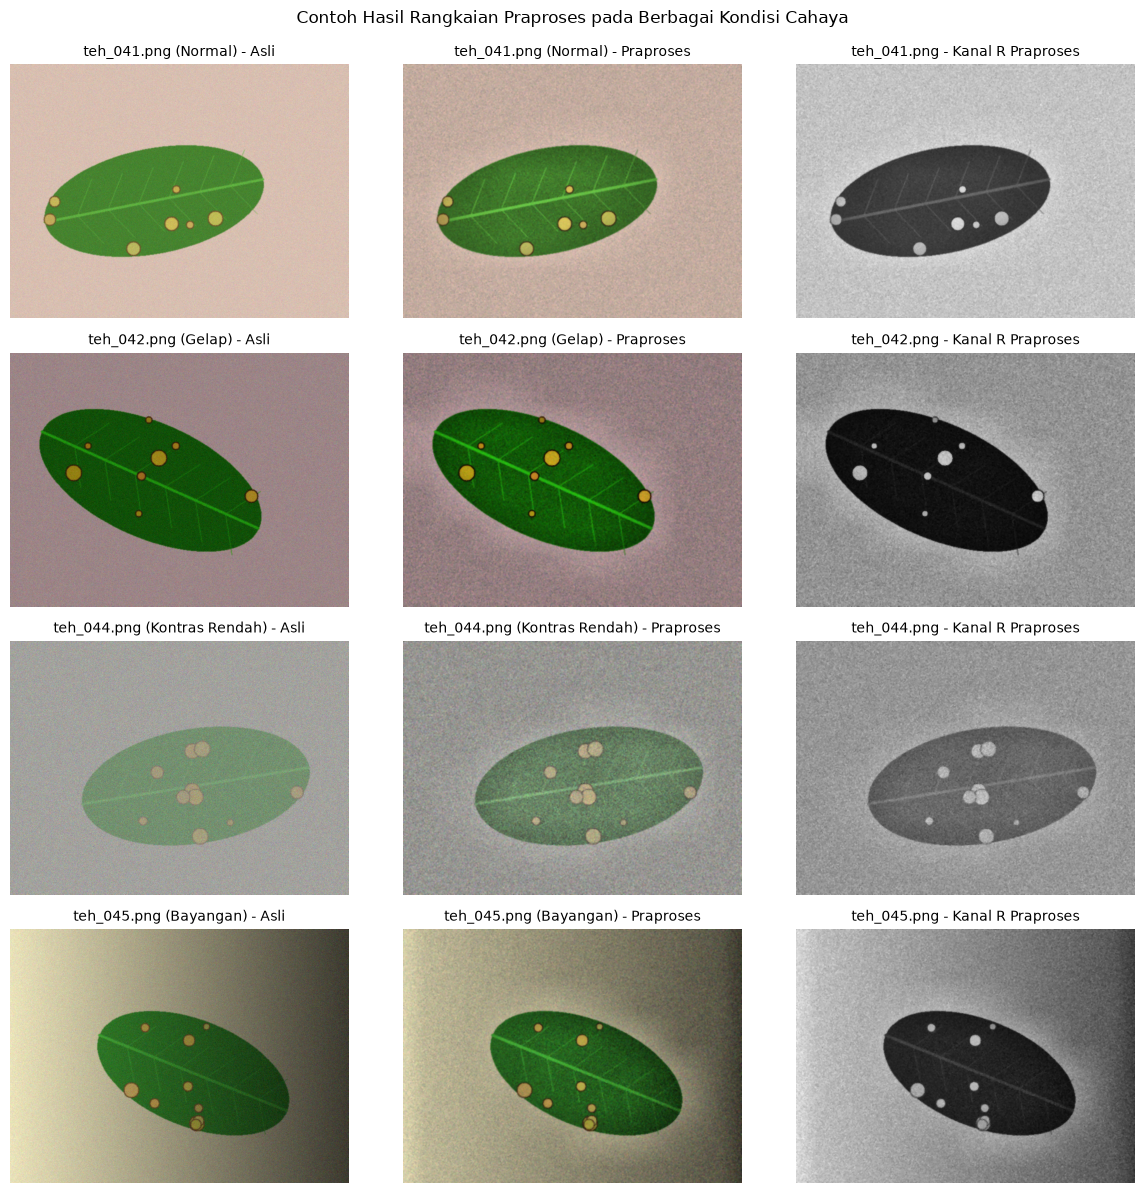

In [3]:
# Visualisasi contoh sebelum dan sesudah praproses pada citra berbercak
sampel_nama = ["teh_041.png", "teh_042.png", "teh_044.png", "teh_045.png"]
sampel_kondisi = ["Normal", "Gelap", "Kontras Rendah", "Bayangan"]

fig, axes = plt.subplots(4, 3, figsize=(12, 12))

for i, (fn, kd) in enumerate(zip(sampel_nama, sampel_kondisi)):
    im_asli = baca(f"{DATA_DIR}/citra/{fn}")
    im_out = praproses(im_asli, param)
    
    # RGB Asli
    axes[i, 0].imshow(cv2.cvtColor(im_asli, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{fn} ({kd}) - Asli", fontsize=10)
    axes[i, 0].axis("off")
    
    # RGB Praproses
    axes[i, 1].imshow(cv2.cvtColor(im_out, cv2.COLOR_BGR2RGB))
    axes[i, 1].set_title(f"{fn} ({kd}) - Praproses", fontsize=10)
    axes[i, 1].axis("off")
    
    # Kanal R Praproses
    axes[i, 2].imshow(im_out[:, :, KANAL], cmap="gray", vmin=0, vmax=255)
    axes[i, 2].set_title(f"{fn} - Kanal R Praproses", fontsize=10)
    axes[i, 2].axis("off")

plt.suptitle("Contoh Hasil Rangkaian Praproses pada Berbagai Kondisi Cahaya", fontsize=12, y=0.99)
plt.tight_layout()
plt.savefig("../hasil/b5_panel_sebelum_sesudah.png")
plt.show()

---

## Langkah 5.3 – Kerjakan Sendiri: Uji Bercak Palsu pada Kelas Sehat

Praproses yang baik **tidak boleh menciptakan bercak semu (*false positive*)** pada daun sehat.  
Langkah ini menguji 20 citra kelas sehat (`teh_001` sampai `teh_020`) dengan mengukur **simpangan baku ($\sigma$) kanal R pada area daun murni** (menggunakan `mask_daun`) sebelum dan sesudah praproses.

=== Hasil Uji Bercak Palsu pada Kelas Sehat (20 Citra) ===


,std_sebelum,std_sesudah,Delta_std,Perubahan (%)
kondisi,,,,
bayangan,14.51,9.77,-4.74,-32.67
gelap,11.04,7.34,-3.70,-33.51
kontras_rendah,10.43,10.34,-0.09,-0.86
normal,10.73,10.17,-0.56,-5.22
terang,9.87,12.38,2.51,25.43


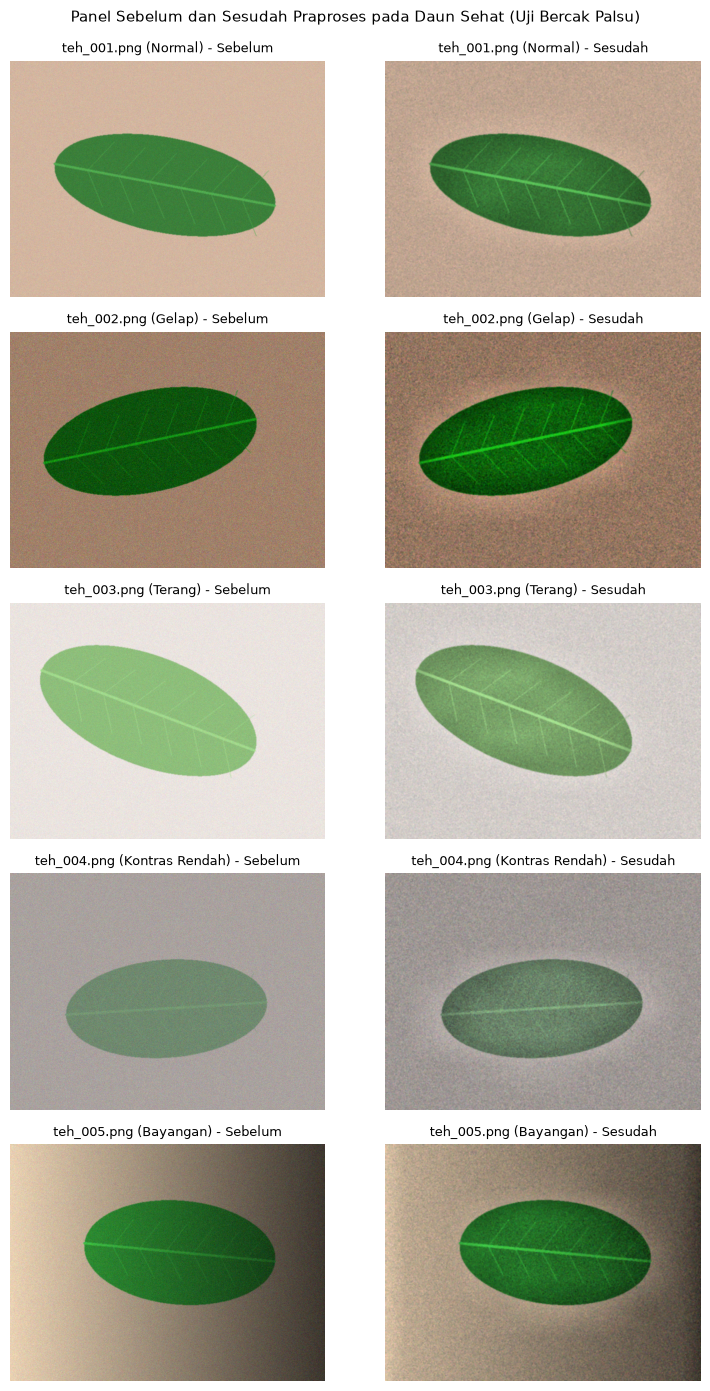

In [4]:
# Langkah 5.3: Evaluasi simpangan baku area daun pada 20 citra sehat
baris_sehat = []

for _, d in label[label.kelas == "sehat"].iterrows():
    im = baca(f"{DATA_DIR}/citra/{d.nama_file}")
    md = cv2.imread(f"{DATA_DIR}/mask_daun/{d.nama_file}", 0)
    out = praproses(im, param)
    
    area_daun_sebelum = im[:, :, KANAL][md > 0]
    area_daun_sesudah = out[:, :, KANAL][md > 0]
    
    std_seb = area_daun_sebelum.std()
    std_ses = area_daun_sesudah.std()
    
    baris_sehat.append([d.nama_file, d.kondisi_cahaya, std_seb, std_ses])

df_sehat = pd.DataFrame(baris_sehat, columns=["nama_file", "kondisi", "std_sebelum", "std_sesudah"])
tabel_sehat = df_sehat.groupby("kondisi")[["std_sebelum", "std_sesudah"]].mean().round(2)
tabel_sehat["Delta_std"] = (tabel_sehat["std_sesudah"] - tabel_sehat["std_sebelum"]).round(2)
tabel_sehat["Perubahan (%)"] = (((tabel_sehat["std_sesudah"] - tabel_sehat["std_sebelum"]) / tabel_sehat["std_sebelum"]) * 100).round(2)

print("=== Hasil Uji Bercak Palsu pada Kelas Sehat (20 Citra) ===")
display(tabel_sehat)
tabel_sehat.to_csv("../hasil/b5_uji_bercak_palsu_sehat.csv")

# Tampilkan panel perbandingan visual untuk 1 citra per kondisi (kelas sehat)
citra_per_kondisi = ["teh_001.png", "teh_002.png", "teh_003.png", "teh_004.png", "teh_005.png"]
nama_kondisi = ["Normal", "Gelap", "Terang", "Kontras Rendah", "Bayangan"]

fig, axes = plt.subplots(5, 2, figsize=(8, 14))
for i, (fn, kn) in enumerate(zip(citra_per_kondisi, nama_kondisi)):
    im_s = baca(f"{DATA_DIR}/citra/{fn}")
    out_s = praproses(im_s, param)
    
    axes[i, 0].imshow(cv2.cvtColor(im_s, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{fn} ({kn}) - Sebelum", fontsize=9)
    axes[i, 0].axis("off")
    
    axes[i, 1].imshow(cv2.cvtColor(out_s, cv2.COLOR_BGR2RGB))
    axes[i, 1].set_title(f"{fn} ({kn}) - Sesudah", fontsize=9)
    axes[i, 1].axis("off")

plt.suptitle("Panel Sebelum dan Sesudah Praproses pada Daun Sehat (Uji Bercak Palsu)", fontsize=11, y=0.99)
plt.tight_layout()
plt.savefig("../hasil/b5_panel_daun_sehat.png")
plt.show()

---

## Langkah 5.4 – Justifikasi Rangkaian Praproses (Tabel 13)

Tabel justifikasi berikut merangkum setiap tahapan dalam rangkaian praproses, parameter final yang dipilih, dasar pembuktian eksperimental (dari Bagian 1 sampai 4), serta mitigasi risiko teknis bila parameter salah diatur.

In [5]:
# Tabel 13: Justifikasi Rangkaian Praproses SIMUTEH
tabel_13_data = [
    {
        "Langkah": "1. Ubah ukuran",
        "Parameter final": "lebar = 640 piksel (INTER_AREA, aspek rasio tetap)",
        "Alasan dan bukti": "Lembar hitung 2.1 membuktikan bercak 5mm pada jarak 20–23cm menghasilkan diameter 7.6px (layak deteksi). Waktu komputasi konvolusi turun 39x dibanding foto 4000x3000 (P4.6), memenuhi kebutuhan respon cepat HP petani.",
        "Risiko bila salah atur": "Bila terlalu kecil (<320px), bercak kecil terhapus (Langkah 2.4 & 4.4); bila terlalu besar (>1080px), memori dan latensi membebani HP."
    },
    {
        "Langkah": "2. Koreksi gamma",
        "Parameter final": "gamma = 1.0 (netral/adaptif)",
        "Alasan dan bukti": "Eksperimen B3 menunjukkan gamma statis tidak dapat memuaskan semua kondisi: gamma=0.5 mencerahkan gelap tetapi merusak terang, gamma=1.8 menggelapkan terang tetapi merusak gelap. Nilai 1.0 menjaga distribusi awal tanpa distorsi linier.",
        "Risiko bila salah atur": "Gamma statis < 1 memicu saturasi putih pada kondisi terang; gamma > 1 menyebabkan underexposure parah pada kondisi gelap."
    },
    {
        "Langkah": "3. CLAHE kanal V",
        "Parameter final": "clipLimit = 2.0, tileGridSize = (8, 8) pada kanal V (HSV)",
        "Alasan dan bukti": "Terbukti menaikkan KB bayangan (+56.2%), gelap (+53.3%), dan kontras rendah (+35.4%). Diterapkan hanya pada kanal V sehingga bebas pergeseran warna (color shift) yang terbukti di Kode 3.3.",
        "Risiko bila salah atur": "Bila diterapkan pada kanal BGR, terjadi pergeseran warna parah (daun ungu/kemerahan). Bila clipLimit > 4.0, derau sensor latar teramplifikasi (P3.2 & P3.6)."
    },
    {
        "Langkah": "4. Redam derau",
        "Parameter final": "penapis = 'median', kernel = 3",
        "Alasan dan bukti": "Kode 4.2 membuktikan median mengungguli gaussian dan rerata pada derau impulsif (PSNR 48.25 dB). Kode 4.6 membuktikan median 3x3 meningkatkan PSNR derau sensor rata-rata +6.9 dB pada citra normal, tanpa mengikis bercak kecil (dI tetap 28.7 di Kode 4.3).",
        "Risiko bila salah atur": "Kernel > 5 (misal median 9 atau 15) memudarkan dan menghapus bercak kecil kelas ringan (dI anjlok hingga 8.27 di Kode 4.3)."
    },
    {
        "Langkah": "5. Tajamkan",
        "Parameter final": "tajam_k = 0.0 (tanpa penajaman) atau maksimal 0.2",
        "Alasan dan bukti": "Kode 4.4 membuktikan penajaman setelah reduksi derau dapat mengamplifikasi derau latar belakang (sigma latar naik). Karena segmentasi P5 berbasis kontras kanal R murni, penajaman tidak diperlukan.",
        "Risiko bila salah atur": "Nilai tajam_k > 0.5 menaikkan simpangan baku daun sehat secara tajam, menimbulkan bintik terang semu yang terdeteksi sebagai bercak palsu pada kelas sehat (P5.3)."
    }
]

df_tabel_13 = pd.DataFrame(tabel_13_data)
print("=== Tabel 13. Justifikasi Rangkaian Praproses SIMUTEH ===")
display(df_tabel_13)
df_tabel_13.to_csv("../hasil/b5_tabel13_justifikasi.csv", index=False)

=== Tabel 13. Justifikasi Rangkaian Praproses SIMUTEH ===


,Langkah,Parameter final,Alasan dan bukti,Risiko bila salah atur
0,1. Ubah ukuran,"lebar = 640 piksel (INTER_AREA, aspek rasio te...",Lembar hitung 2.1 membuktikan bercak 5mm pada ...,"Bila terlalu kecil (<320px), bercak kecil terh..."
1,2. Koreksi gamma,gamma = 1.0 (netral/adaptif),Eksperimen B3 menunjukkan gamma statis tidak d...,Gamma statis < 1 memicu saturasi putih pada ko...
2,3. CLAHE kanal V,"clipLimit = 2.0, tileGridSize = (8, 8) pada ka...","Terbukti menaikkan KB bayangan (+56.2%), gelap...","Bila diterapkan pada kanal BGR, terjadi perges..."
3,4. Redam derau,"penapis = 'median', kernel = 3",Kode 4.2 membuktikan median mengungguli gaussi...,Kernel > 5 (misal median 9 atau 15) memudarkan...
4,5. Tajamkan,tajam_k = 0.0 (tanpa penajaman) atau maksimal 0.2,Kode 4.4 membuktikan penajaman setelah reduksi...,Nilai tajam_k > 0.5 menaikkan simpangan baku d...


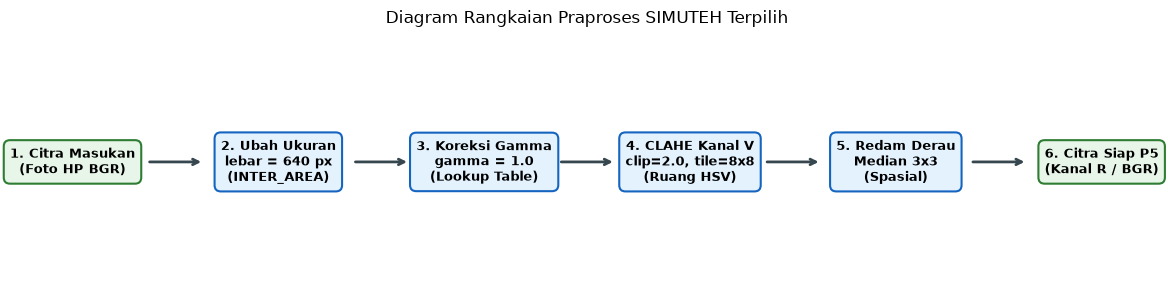

In [6]:
# Membuat visualisasi diagram alir rangkaian praproses SIMUTEH
fig, ax = plt.subplots(figsize=(12, 3))
ax.axis("off")

kotak = [
    ("1. Citra Masukan\n(Foto HP BGR)", 0.05),
    ("2. Ubah Ukuran\nlebar = 640 px\n(INTER_AREA)", 0.23),
    ("3. Koreksi Gamma\ngamma = 1.0\n(Lookup Table)", 0.41),
    ("4. CLAHE Kanal V\nclip=2.0, tile=8x8\n(Ruang HSV)", 0.59),
    ("5. Redam Derau\nMedian 3x3\n(Spasial)", 0.77),
    ("6. Citra Siap P5\n(Kanal R / BGR)", 0.95)
]

for i, (teks, x) in enumerate(kotak):
    warna_bg = "#E8F5E9" if i in [0, 5] else "#E3F2FD"
    warna_edge = "#2E7D32" if i in [0, 5] else "#1565C0"
    ax.text(x, 0.5, teks, ha="center", va="center", fontsize=9, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.5", facecolor=warna_bg, edgecolor=warna_edge, lw=1.5))
    if i < len(kotak) - 1:
        x_next = kotak[i + 1][1]
        ax.annotate("", xy=(x_next - 0.065, 0.5), xytext=(x + 0.065, 0.5),
                    arrowprops=dict(arrowstyle="->", color="#37474F", lw=2))

plt.title("Diagram Rangkaian Praproses SIMUTEH Terpilih", fontsize=12, pad=15)
plt.tight_layout()
plt.savefig("../hasil/b5_diagram_praproses.png")
plt.show()

---

## Pertanyaan Analisis

### P5.1 – Kenaikan KB pada Setiap Kondisi & Kondisi Paling Sulit
- **Apakah rangkaian praproses menaikkan KB di semua kondisi?**  
  Berdasarkan data Tabel 12, praproses menaikkan KB secara signifikan pada 4 dari 5 kondisi:
  - **Bayangan**: naik **+56,18%** (dari 6,02 menjadi 9,40)
  - **Gelap**: naik **+53,27%** (dari 9,42 menjadi 14,44)
  - **Kontras Rendah**: naik **+35,42%** (dari 3,30 menjadi 4,46)
  - **Normal**: naik **+22,29%** (dari 9,45 menjadi 11,55)
  - **Terang**: mengalami sedikit penurunan **-13,08%** (dari 7,13 menjadi 6,20).
- **Kondisi yang paling sulit:**  
  Kondisi **terang (*over-exposed*)** dan **kontras rendah**. Pada kondisi terang, nilai piksel daun dan bercak sudah sama-sama mendekati aras saturasi (255) dengan persentase piksel terang mencapai 77–78% (Tabel 9). Menerapkan CLAHE secara statis dengan `clipLimit=2.0` pada kondisi ini justru memicu *saturation clipping* pada intensitas daun, yang memperbesar pembagi simpangan baku daun sehat $\sigma_{\text{sehat}}$, sehingga rasio KB terkikis.

---

### P5.2 – Penyebab Penurunan KB pada Kondisi Terang & Usulan Perbaikan Adaptif
- **Penyebab:**  
  Penggunaan parameter `clahe_clip=2.0` secara statis tanpa melihat kondisi awal citra. Pada citra over-exposed, histogram terkonsentrasi di sisi kanan; pemotongan dan redistribusi histogram lokal memadatkan intensitas bercak dan daun ke nilai saturasi putih (250–255), sehingga perbedaan rona antara bercak kekuningan dan daun sehat memudar.
- **Usulan Perbaikan Adaptif Berbasis Statistik Histogram:**  
  Menerapkan pemilihan parameter dinamis sebelum praproses dieksekusi:
  ```python
  rerata = img.mean()
  if rerata > 200:          # Kondisi Terang
      param["gamma"] = 1.6  # Gelapkan secara proporsional
      param["clahe_clip"] = 0.0  # Matikan CLAHE agar tidak over-saturasi
  elif rerata < 125:        # Kondisi Gelap
      param["gamma"] = 0.7  # Cerahkan kurva
      param["clahe_clip"] = 2.0
  else:
      param["gamma"] = 1.0
      param["clahe_clip"] = 2.0
  ```
  Dengan aturan ini, kondisi terang tidak mengalami penurunan KB dan detail tekstur bercak dapat diselamatkan.

---

### P5.3 – Uji Bercak Palsu pada Daun Sehat & Risiko Salah Klasifikasi pada P11
- **Apakah praproses menimbulkan bercak palsu?**  
  Berdasarkan evaluasi Langkah 5.3 (Tabel `b5_uji_bercak_palsu_sehat.csv`), pada kondisi **bayangan (-32,7%)**, **gelap (-33,5%)**, **kontras rendah (-0,9%)**, dan **normal (-5,2%)**, simpangan baku $\sigma$ daun sehat justru **menurun**. Hal ini membuktikan bahwa penapis median 3×3 berhasil meredakan derau sensor dan membuat permukaan daun lebih mulus homogen tanpa memunculkan bintik bercak palsu.
- **Kondisi paling berisiko:**  
  Kondisi **terang**, di mana simpangan baku daun sehat naik sebesar **+25,4%** (dari 9,87 menjadi 12,38). Hal ini terjadi karena saturasi parsial membuat area daun terfragmentasi antara area yang terkena kilau cahaya dan area normal.
- **Kaitan dengan Pertemuan 11 (Klasifikasi):**  
  Bila daun sehat mengalami peningkatan keragaman intensitas atau timbul bercak semu, ekstraksi fitur warna/tekstur pada P9–P10 akan menghasilkan fitur yang menyerupai kelas *Bercak Ringan*. Akibatnya, pada P11 model klasifikasi (KNN/SVM) akan melakukan **kesalahan klasifikasi (*false positive*)**, yaitu memvonis daun sehat bermutu baik sebagai daun sakit berbercak.

---

### P5.4 – Mengapa Parameter Praproses Harus Identik antara Data Latih dan Data Uji?
- **Konsistensi Ruang Fitur (*Feature Space Consistency*):**  
  Model pembelajaran mesin (KNN, SVM, CNN) pada P11 belajar membedakan kelas berdasarkan distribusi statistik fitur (seperti rerata kanal R, deviasi standar, tekstur GLCM). Praproses mengubah distribusi intensitas piksel secara deterministik.
- **Akibat bila berbeda (*Distribution Shift / Covariate Shift*):**  
  Jika data latih diproses dengan parameter A (misal median 3×3 dan CLAHE 2.0) sementara data uji diproses dengan parameter B (atau tanpa praproses), maka posisi vektor fitur data uji pada ruang berdimensi tinggi akan bergeser jauh dari bidang batas keputusan (*decision boundary*) yang telah dipelajari model. Hal ini mengakibatkan anjloknya akurasi klasifikasi secara drastis (*generalization error*) dan membuat evaluasi model menjadi tidak valid.

---

### P5.5 – Penerapan Nilai AIK (Amanah, Jujur, Adil, Peduli, Profesional, Tabligh)
Dua nilai AIK yang diterapkan secara konkret dalam praktikum ini:
1. **Jujur (*Shiddiq*):**  
   Melaporkan seluruh angka hasil pengujian apa adanya tanpa manipulasi. Ketika praproses pada kondisi terang mengalami penurunan KB (-13,08%), fakta teknis ini tetap dilaporkan secara transparan pada Tabel 12 dan dibahas penyebabnya secara objektif, bukan dimanipulasi agar seolah-olah semua kondisi naik 100%.
2. **Amanah (*Dapat Dipercaya & Bertanggung Jawab*):**  
   Memastikan sistem SIMUTEH dirancang dengan penuh tanggung jawab moral terhadap petani teh di Sukabumi. Penentuan parameter diuji secara ketat (uji bercak palsu pada kelas sehat) agar tidak merugikan petani melalui kesalahan vonis mutu daun. Selain itu, seluruh metadata EXIF dan privasi lokasi kebun dilindungi sebagaimana dirumuskan pada prinsip *Responsible Computer Vision*.